# Praktikum Data Mining — Association Rule Mining (Market Basket Analysis)
**Program Studi Informatika — Universitas Negeri Padang**

Notebook ini memuat langkah-langkah praktikum pada Bagian 4 (4.1–4.8). Pengerjaan Tugas 1–4 ada di notebook terpisah: `Praktikum_ARM_2_Tugas.ipynb`.
Dua dataset yang disediakan digunakan bersama:

| Dataset | Berkas | Format | Kegunaan |
|---|---|---|---|
| Dataset 1 | `transactions_arm_praktikum.csv` | daftar item per transaksi (TID, Items) | sumber utama; di-encode dengan `TransactionEncoder` |
| Dataset 2 | `transactions_arm_praktikum_onehot.csv` | matriks one-hot 60 × 12 | verifikasi hasil encoding dan hasil mining |

> Isi nama dan NIM Anda pada sel berikut sebelum membuat laporan.

### 0. Pemeriksaan berkas data
Pastikan dua berkas CSV berada di folder yang sama dengan notebook. Pustaka `mlxtend` cukup dipasang sekali lewat Anaconda Prompt (`pip install mlxtend`).

In [1]:
# Jika mlxtend belum terpasang, jalankan sekali di Anaconda Prompt:  pip install mlxtend
# (jangan memakai %pip di dalam notebook agar tidak bentrok dengan matplotlib yang sudah termuat)
import os
for f in ['transactions_arm_praktikum.csv', 'transactions_arm_praktikum_onehot.csv']:
    print(f, '->', 'ditemukan' if os.path.exists(f) else 'BELUM ADA, letakkan di folder notebook')

transactions_arm_praktikum.csv -> ditemukan
transactions_arm_praktikum_onehot.csv -> ditemukan


In [2]:
NAMA = "Nama Mahasiswa"
NIM  = "NIM"
KELAS = "Kelas"

## 4.1 Persiapan Data Transaksi

In [3]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules

os.makedirs('figs', exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
NAVY = '#1E2761'

In [4]:
# Dataset 1: daftar item per transaksi
raw = pd.read_csv('transactions_arm_praktikum.csv')
transactions = [[i.strip() for i in s.split(',')] for s in raw['Items']]

print('Jumlah transaksi:', len(transactions))
for i, t in enumerate(transactions[:5], 1):
    print(f'T{i}: {t}')

Jumlah transaksi: 60
T1: ['Gula', 'Kopi', 'Susu']
T2: ['Gula', 'Kopi', 'Susu']
T3: ['Mentega', 'Roti', 'Susu', 'Telur']
T4: ['Mie Instan']
T5: ['Keju', 'Roti', 'Susu', 'Telur']


In [5]:
cnt = Counter()
for t in transactions:
    cnt.update(t)
for item, freq in cnt.most_common():
    print(f'{item:12s}: {freq:2d} (support = {freq/len(transactions):.3f})')

Susu        : 19 (support = 0.317)
Roti        : 18 (support = 0.300)
Mie Instan  : 18 (support = 0.300)
Mentega     : 17 (support = 0.283)
Telur       : 15 (support = 0.250)
Sabun       : 15 (support = 0.250)
Gula        : 14 (support = 0.233)
Kopi        : 13 (support = 0.217)
Shampo      : 13 (support = 0.217)
Kecap       : 12 (support = 0.200)
Keju        :  6 (support = 0.100)
Teh         :  4 (support = 0.067)


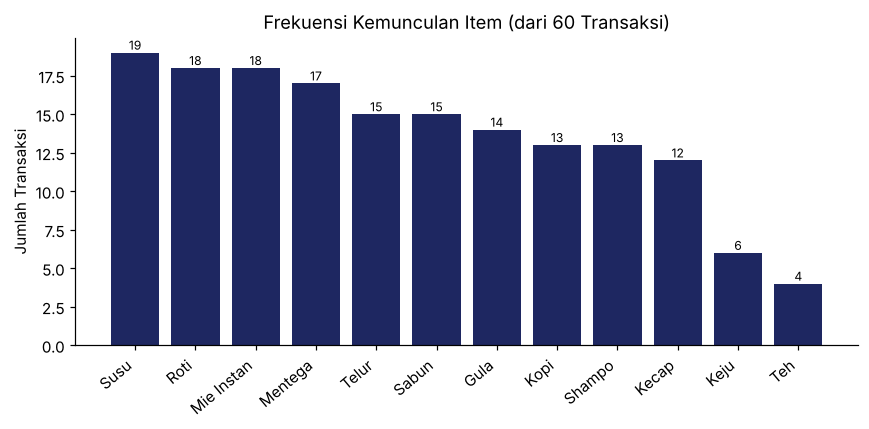

In [6]:
items, freqs = zip(*cnt.most_common())
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(items, freqs, color=NAVY)
ax.bar_label(bars, fontsize=8)
ax.set_ylabel('Jumlah Transaksi')
ax.set_title('Frekuensi Kemunculan Item (dari 60 Transaksi)')
plt.xticks(rotation=40, ha='right')
plt.tight_layout(); plt.savefig('figs/gambar2_frekuensi_item.png'); plt.show()

## 4.2 Encoding Data Transaksi ke Format One-Hot

In [7]:
te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df = pd.DataFrame(te_ary, columns=te.columns_)

print('Ukuran matriks one-hot:', df.shape)
print(df.iloc[:5, :6])

Ukuran matriks one-hot: (60, 12)
    Gula  Kecap   Keju   Kopi  Mentega  Mie Instan
0   True  False  False   True    False       False
1   True  False  False   True    False       False
2  False  False  False  False     True       False
3  False  False  False  False    False        True
4  False  False   True  False    False       False


### Dataset 2 (one-hot): verifikasi silang terhadap hasil encoding Dataset 1

In [8]:
df_oh = pd.read_csv('transactions_arm_praktikum_onehot.csv').astype(bool)
print('Ukuran Dataset 2:', df_oh.shape)
print('Kolom sama     :', list(df.columns) == list(df_oh.columns))
print('Isi sama persis:', bool((df.values == df_oh.values).all()))

Ukuran Dataset 2: (60, 12)
Kolom sama     : True
Isi sama persis: True


## 4.3 Mencari Frequent Itemset dengan Apriori

In [9]:
MIN_SUP = 0.15
freq_apriori = apriori(df, min_support=MIN_SUP, use_colnames=True)
freq_apriori = freq_apriori.sort_values('support', ascending=False)
print('Jumlah frequent itemset:', len(freq_apriori))
print(freq_apriori.round(3).to_string(index=False))

Jumlah frequent itemset: 17
 support                         itemsets
   0.317                frozenset({Susu})
   0.300                frozenset({Roti})
   0.300          frozenset({Mie Instan})
   0.283             frozenset({Mentega})
   0.250               frozenset({Sabun})
   0.250               frozenset({Telur})
   0.233                frozenset({Gula})
   0.217              frozenset({Shampo})
   0.217                frozenset({Kopi})
   0.217          frozenset({Susu, Roti})
   0.217       frozenset({Roti, Mentega})
   0.200               frozenset({Kecap})
   0.183       frozenset({Susu, Mentega})
   0.183 frozenset({Susu, Roti, Mentega})
   0.167   frozenset({Telur, Mie Instan})
   0.150   frozenset({Kecap, Mie Instan})
   0.150       frozenset({Sabun, Shampo})


**Analisis.** Dengan `min_support = 0.15` (minimal 9 dari 60 transaksi) diperoleh 17 frequent itemset: 10 itemset tunggal, 6 pasangan, dan 1 itemset tiga item `{Mentega, Roti, Susu}`. Keju (support 0.100) dan Teh (0.067) gugur pada level 1-itemset. `{Mentega, Roti, Susu}` (support 0.183, 11 transaksi) menunjukkan pola paket sarapan. Dataset 2 (one-hot) menghasilkan himpunan itemset yang identik.

In [10]:
# Dataset 2 harus menghasilkan frequent itemset yang sama
fi2 = apriori(df_oh, min_support=MIN_SUP, use_colnames=True)
print('Itemset Dataset 1 == Dataset 2:',
      set(map(frozenset, freq_apriori['itemsets'])) == set(map(frozenset, fi2['itemsets'])))

Itemset Dataset 1 == Dataset 2: True


## 4.4 Membentuk Aturan Asosiasi

In [11]:
MIN_CONF = 0.5
rules = association_rules(freq_apriori, num_itemsets=len(df), metric='confidence', min_threshold=MIN_CONF)
rules = rules.sort_values('lift', ascending=False).reset_index(drop=True)

def fmt(s): return ', '.join(sorted(s))
rules['aturan'] = rules['antecedents'].apply(fmt) + ' → ' + rules['consequents'].apply(fmt)

print('Jumlah aturan asosiasi:', len(rules))
cols = ['aturan', 'support', 'confidence', 'lift']
print(rules[cols].round(3).to_string(index=False))
rules.drop(columns=['aturan']).to_csv('rules.csv', index=False)

Jumlah aturan asosiasi: 18
              aturan  support  confidence  lift
Roti → Mentega, Susu    0.183       0.611 3.333
Mentega, Susu → Roti    0.183       1.000 3.333
Mentega → Roti, Susu    0.183       0.647 2.986
Roti, Susu → Mentega    0.183       0.846 2.986
      Shampo → Sabun    0.150       0.692 2.769
      Sabun → Shampo    0.150       0.600 2.769
Susu → Mentega, Roti    0.183       0.579 2.672
Mentega, Roti → Susu    0.183       0.846 2.672
      Roti → Mentega    0.217       0.722 2.549
      Mentega → Roti    0.217       0.765 2.549
  Mie Instan → Kecap    0.150       0.500 2.500
  Kecap → Mie Instan    0.150       0.750 2.500
         Roti → Susu    0.217       0.722 2.281
         Susu → Roti    0.217       0.684 2.281
  Mie Instan → Telur    0.167       0.556 2.222
  Telur → Mie Instan    0.167       0.667 2.222
      Susu → Mentega    0.183       0.579 2.043
      Mentega → Susu    0.183       0.647 2.043


**Analisis.** Dihasilkan 18 aturan. Aturan dengan Lift tertinggi adalah `Mentega, Susu → Roti` (support 0.183; confidence 1.000; lift 3.333) dan kebalikannya `Roti → Mentega, Susu` (lift sama, confidence 0.611). Lift setiap pasangan aturan simetris karena Lift = support(X∪Y) / (support(X)·support(Y)), sedangkan Confidence bergantung pada arah aturan. Seluruh aturan memiliki Lift > 1 (2.04–3.33), sehingga semuanya berkorelasi positif.

## 4.5 Visualisasi Hasil

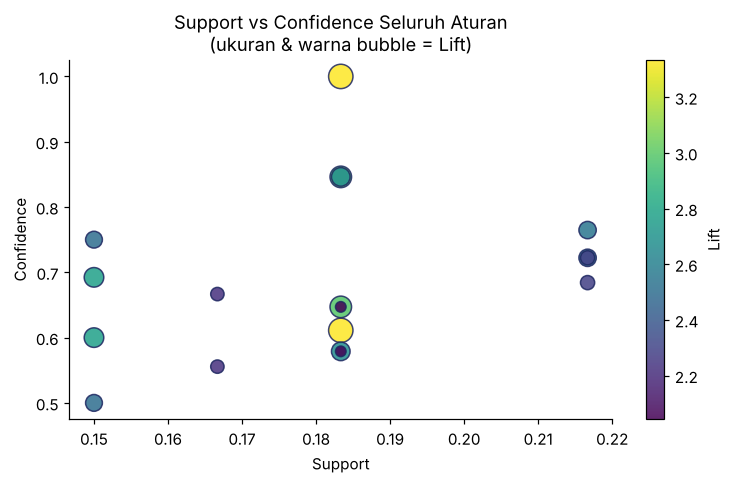

In [12]:
sizes = (rules['lift'] - rules['lift'].min() + 0.3) * 160
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(rules['support'], rules['confidence'], s=sizes, c=rules['lift'],
                cmap='viridis', alpha=0.85, edgecolor=NAVY)
plt.colorbar(sc, label='Lift')
ax.set_xlabel('Support'); ax.set_ylabel('Confidence')
ax.set_title('Support vs Confidence Seluruh Aturan\n(ukuran & warna bubble = Lift)')
plt.tight_layout(); plt.savefig('figs/gambar3_scatter_aturan.png'); plt.show()

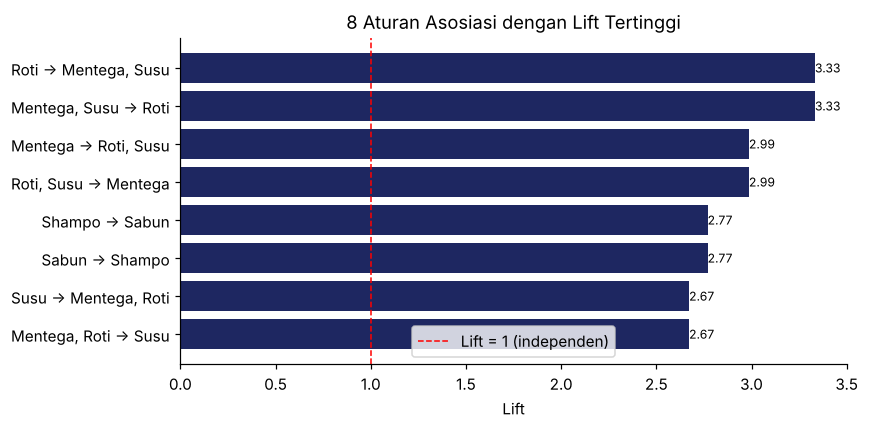

In [13]:
top8 = rules.head(8).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4))
b = ax.barh(top8['aturan'], top8['lift'], color=NAVY)
ax.bar_label(b, fmt='%.2f', fontsize=8)
ax.axvline(1, color='red', ls='--', lw=1, label='Lift = 1 (independen)')
ax.set_xlabel('Lift'); ax.set_title('8 Aturan Asosiasi dengan Lift Tertinggi'); ax.legend()
plt.tight_layout(); plt.savefig('figs/gambar4_top8_lift.png'); plt.show()

## 4.6 Interpretasi Bisnis dari Aturan Terpilih

In [14]:
def cari(ant, con):
    r = rules[(rules['antecedents'] == frozenset(ant)) & (rules['consequents'] == frozenset(con))].iloc[0]
    return r
for ant, con in [(['Mentega','Susu'],['Roti']), (['Sabun'],['Shampo']), (['Kecap'],['Mie Instan'])]:
    r = cari(ant, con)
    print(f"{fmt(r['antecedents'])} → {fmt(r['consequents'])}: support={r['support']:.3f}, "
          f"confidence={r['confidence']:.3f}, lift={r['lift']:.3f}")

Mentega, Susu → Roti: support=0.183, confidence=1.000, lift=3.333
Sabun → Shampo: support=0.150, confidence=0.600, lift=2.769
Kecap → Mie Instan: support=0.150, confidence=0.750, lift=2.500


## 4.7 Eksperimen: Pengaruh Nilai min_support

In [15]:
sweep_sup = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40]
res_sup = []
for s in sweep_sup:
    fi = apriori(df, min_support=s, use_colnames=True)
    r = association_rules(fi, num_itemsets=len(df), metric='confidence', min_threshold=0.5) if len(fi) else pd.DataFrame()
    res_sup.append((s, len(fi), len(r)))
    print(f'min_support={s:.2f}: {len(fi):2d} itemset, {len(r):2d} aturan')

min_support=0.10: 19 itemset, 20 aturan
min_support=0.15: 17 itemset, 18 aturan
min_support=0.20: 12 itemset,  4 aturan
min_support=0.25:  6 itemset,  0 aturan
min_support=0.30:  3 itemset,  0 aturan
min_support=0.35:  0 itemset,  0 aturan
min_support=0.40:  0 itemset,  0 aturan


**Analisis.** Jumlah aturan turun lebih tajam daripada jumlah itemset: pada `min_support = 0.20` tersisa 12 itemset tetapi hanya 4 aturan, karena sebagian besar itemset yang bertahan adalah itemset tunggal (tidak dapat membentuk aturan X → Y). Mulai `min_support = 0.35` tidak ada itemset yang lolos karena support tertinggi (Susu) hanya 0.317.

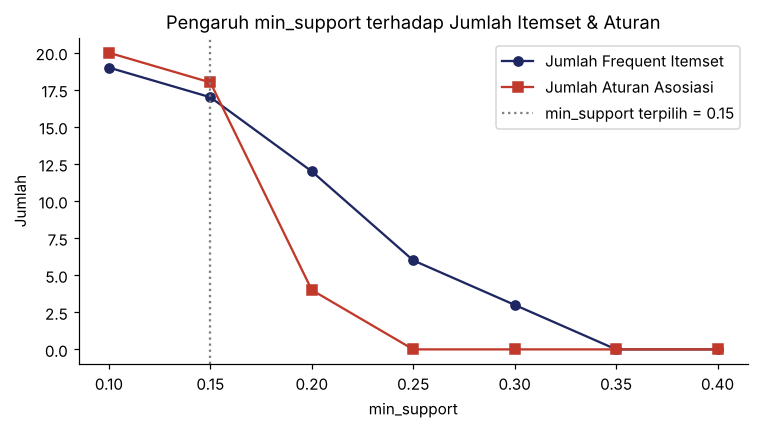

In [16]:
x, a, b = zip(*res_sup)
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, a, 'o-', color=NAVY, label='Jumlah Frequent Itemset')
ax.plot(x, b, 's-', color='#C0392B', label='Jumlah Aturan Asosiasi')
ax.axvline(0.15, color='gray', ls=':', label='min_support terpilih = 0.15')
ax.set_xlabel('min_support'); ax.set_ylabel('Jumlah')
ax.set_title('Pengaruh min_support terhadap Jumlah Itemset & Aturan'); ax.legend()
plt.tight_layout(); plt.savefig('figs/gambar5_sweep_support.png'); plt.show()

## 4.8 Eksperimen: Apriori vs FP-Growth (min_support = 0.15)

In [17]:
def bandingkan(data, sup, ulang=30):
    # waktu = rata-rata dari beberapa kali pengulangan agar lebih stabil
    ta, tf = [], []
    for _ in range(ulang):
        t0 = time.perf_counter(); fa = apriori(data, min_support=sup, use_colnames=True); ta.append(time.perf_counter() - t0)
        t0 = time.perf_counter(); ff = fpgrowth(data, min_support=sup, use_colnames=True); tf.append(time.perf_counter() - t0)
    same = set(map(frozenset, fa['itemsets'])) == set(map(frozenset, ff['itemsets']))
    return len(fa), len(ff), np.mean(ta)*1000, np.mean(tf)*1000, same

n_a, n_f, t_a, t_f, same = bandingkan(df, 0.15)
print(f'Apriori  : {n_a} itemset, {t_a:.2f} ms')
print(f'FP-Growth: {n_f} itemset, {t_f:.2f} ms')
print('Itemset identik?', same)

Apriori  : 17 itemset, 1.60 ms
FP-Growth: 17 itemset, 1.13 ms
Itemset identik? True


**Analisis.** Kedua algoritma menghasilkan 17 itemset yang sama persis. Pada dataset sekecil ini selisih waktunya hanya hitungan milidetik dan dapat berubah antar eksekusi, sehingga waktu dihitung sebagai rata-rata dari 30 kali pengulangan.

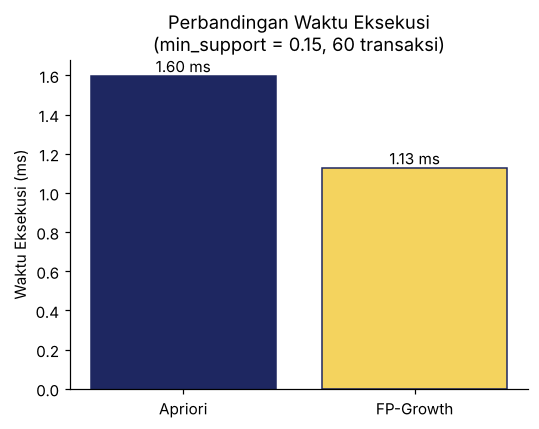

In [18]:
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['Apriori', 'FP-Growth'], [t_a, t_f], color=[NAVY, '#F4D35E'], edgecolor=NAVY)
ax.bar_label(bars, fmt='%.2f ms')
ax.set_ylabel('Waktu Eksekusi (ms)'); ax.set_title('Perbandingan Waktu Eksekusi\n(min_support = 0.15, 60 transaksi)')
plt.tight_layout(); plt.savefig('figs/gambar6_waktu_015.png'); plt.show()